# MARL Practical Session: Part 2

In [ ]:
!pip install gymnasium pettingzoo matplotlib seaborn > /dev/null 2>&1

In [ ]:
from typing import Callable, Tuple, List, Iterable
from collections import Counter
import numpy as np
import random
import matplotlib.pyplot as plt

import gymnasium as gym
from gymnasium import spaces
from pettingzoo import ParallelEnv

For this exercise session, you will implement commitment sequences ~\cite{kapetanakis2004learning}. Commitment sequences are a mechanism to enable the learning of coordination in cooperative multi-agent systems. In order to illustrate the complex interactions between two or more agents when they learn to coordinate cooperative single-stage games are often used. A single-stage game defines one or more outcomes for every possible joint action the agents may undertake in the form of a payoff matrix. In this session, we focus only on cooperative games, i.e., games where the agents are rewarded based on their joint action and all receive the same reward.

The following table describes the reward function for a particular kind of coordination game called the climbing game.

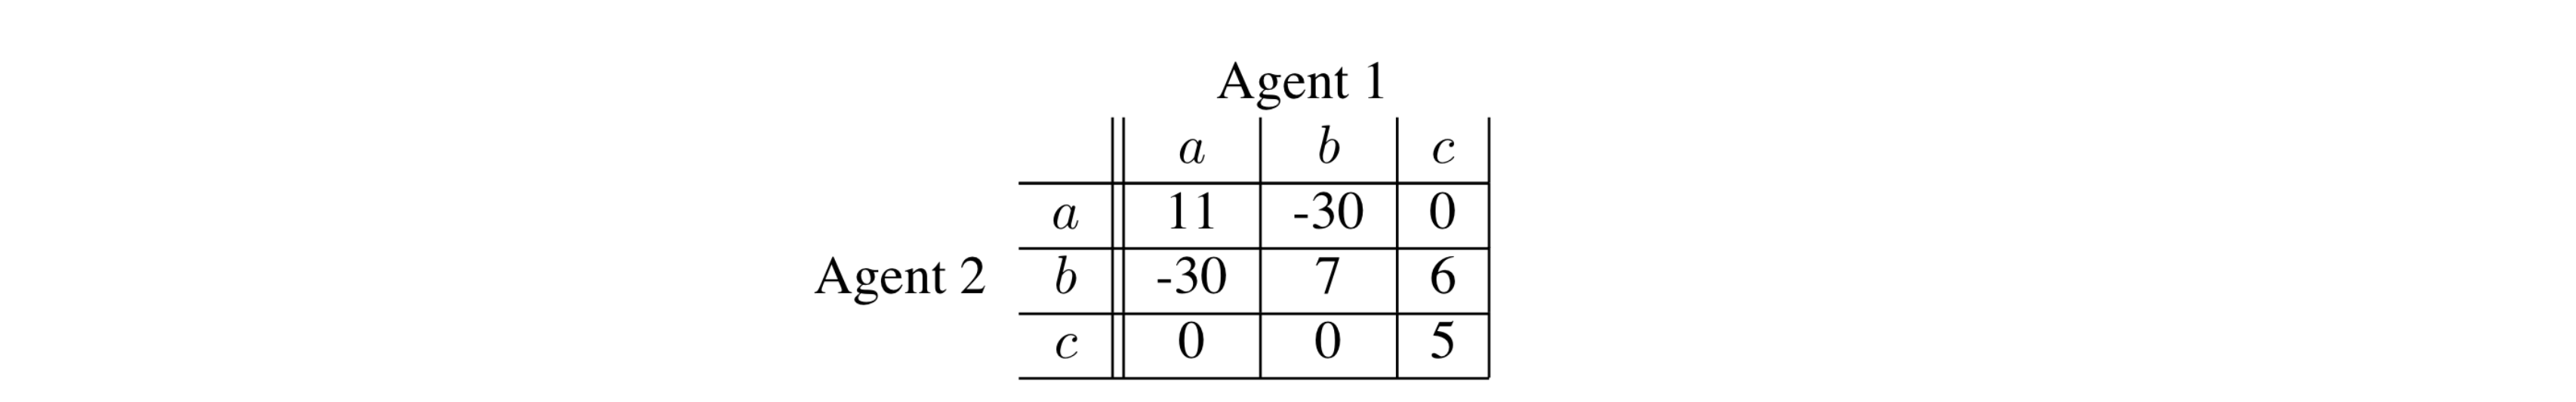

In the climbing game, it is difficult for the agents to converge to the optimal joint action $(a, a)$ because of the negative reward in the case of miscoordination. For example, if agent 1 plays $a$ and agent 2 plays $b$, then both will receive a negative reward of -30. Incorporating this reward into the learning process can be so detrimental that both agents tend to avoid playing the same action again. In contrast, when choosing action $c$, miscoordination is not punished so severely. Therefore, in most cases, both agents are easily tempted by action $c$. The reason is as follows if agent 1 plays $c$, then agent 2 can play either $b$ or $c$ to get a positive reward (6 and 5 respectively). Even if agent 2 plays a, the result is not catastrophic since the reward is 0. The same holds for agent 2.

A more complex variant of the climbing game is the stochastic climbing game.

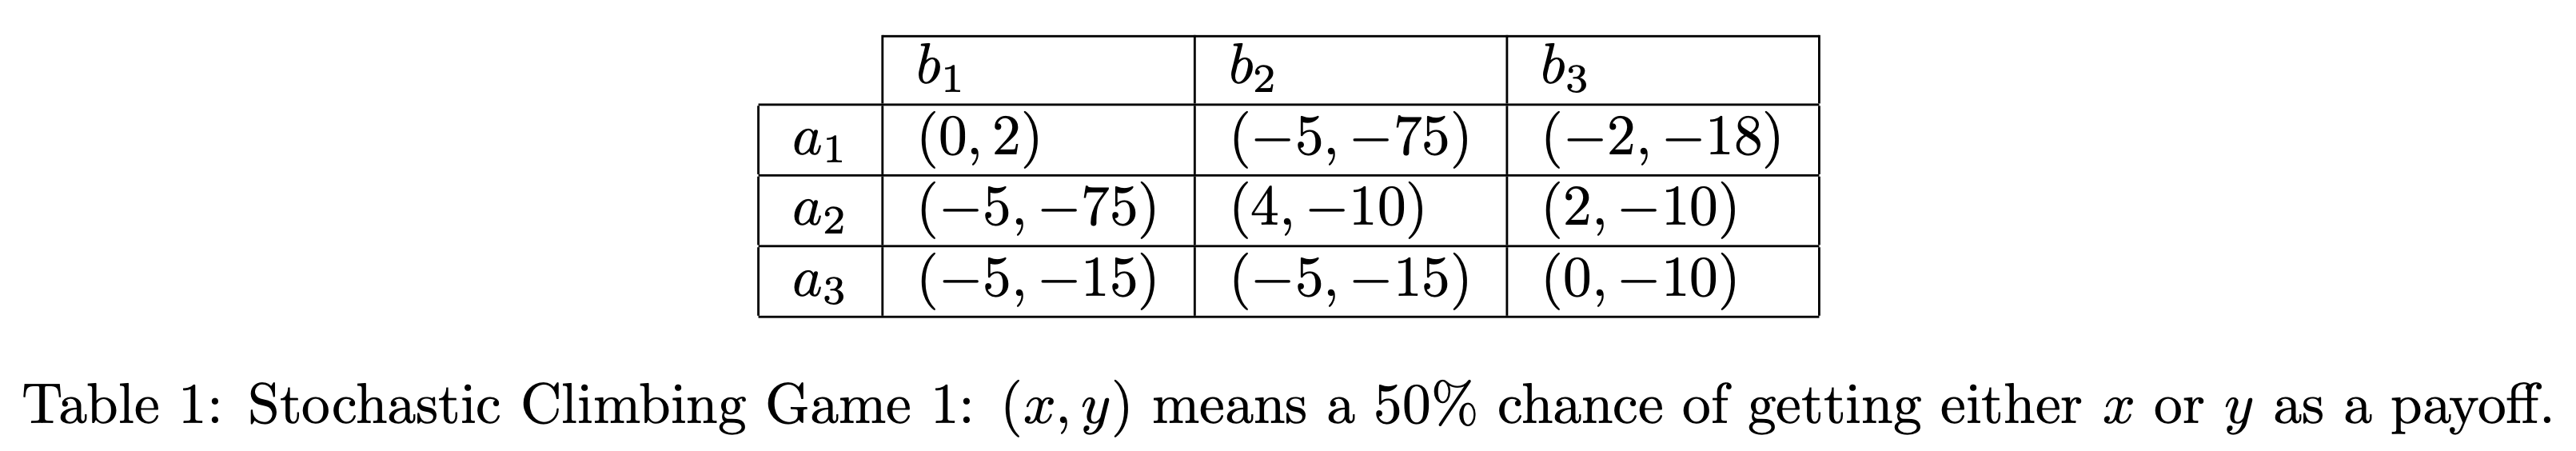

The stochastic version of the climbing game differs from the original in that each joint action now corresponds to two rewards instead of just one. These two rewards are received with probability $\frac{1}{2}$. If the two agents were to commit to playing a specific joint action indefinitely, the reward they would accumulate over time would converge to the same value as in the original game. In this respect, the stochastic climbing game is equivalent to the original.

The difference in the stochastic version of the climbing game is that there are now two sources of uncertainty in the game:
* the other agent’s actions (as before)
* the multiple rewards per joint action.

We will use the stochastic climbing game to illustrate the working of commitment sequences. The following code implements the stochastic climbing game.

In [ ]:
class MatrixGame:
    """
    Matrix Game environment.
    """

    def __init__(self, reward_matrix: np.ndarray):
        """
        :param reward_matrix: Array of shape (nbr_actions_agent_1, ..., nbr_actions_agent_2). The elements of this array
               can be the reward or a callable that returns the reward.
        """
        self.reward_matrix = reward_matrix
        self.num_agents = len(reward_matrix.shape)
        self.num_actions = reward_matrix.shape[0]

    def act(self, action: Iterable[int]):
        """
        Method to perform an action in the Matrix Game and obtain the associated reward.
        :param action: The joint action.
        :return: The reward.
        """
        if not isinstance(action, np.ndarray):
            action = np.array(action)
        assert len(action) == self.num_agents
        assert np.all(0 <= action), "One action is negative."
        assert np.all(action < self.num_actions), "One action is out of bound."
        r = self.reward_matrix[tuple(action)]
        if callable(r):
            r = r()
        return r

def dual_stochastic_reward(p: float, reward_1: float, reward_2: float) -> Callable[[], float]:
    """
    Function that return a callable that return reward_1 with probability p and reward_2 with probability 1 - p.

    :param p: The probability to sample reward_1.
    :param reward_1: The first reward.
    :param reward_2: The second reward.
    :return: A callable that samples a reward.
    """
    assert 0 <= p <= 1, 'p should be in [0,1].'

    def sampler():
        return np.random.choice([reward_1, reward_2], p=[p, 1 - p])

    return sampler


class StochasticClimbingGame(MatrixGame):
    def __init__(self):
        r = np.array(
            [
                [dual_stochastic_reward(0.5, 10, 12), dual_stochastic_reward(0.5, 5, -65), dual_stochastic_reward(0.5, 8, 8)],
                [dual_stochastic_reward(0.5, 5, -65), dual_stochastic_reward(0.5, 14, 0), dual_stochastic_reward(0.5, 12, 0)],
                [dual_stochastic_reward(0.5, 5, -5), dual_stochastic_reward(0.5, 5, -5), dual_stochastic_reward(0.5, 10, 0)],
            ]
        )
        super(StochasticClimbingGame, self).__init__(reward_matrix=r)

# Commitment Sequences
## What is a commitment sequence?
A commitment sequence is some list of time slots $(t_0, t_1, ...)$ for which an agent is committed to taking the same action. If all the agents have the same protocol for defining these sequences, then they are committed to selecting the same joint-action for every time point in the sequence. Although each agent does not know the action choices of the other agents, it can be certain that observed rewards will be statistically stationary and represent unbiased samples for the reward distribution of the same joint action.
## How to generate commitment sequences?
A few conditions need to be met for this technique:
* An exponentially increasing time interval between successive time slots for the same action pair;
* A common global clock to time the actions;
* A shared protocol for defining the commitment sequences.

In order to allow an arbitrarily high number of joint actions and consequently commitment sequences to be considered as the agent learns, it is necessary that the sequences are finite or have an exponentially increasing time interval $\delta_i = t_{i+1} - t_i$ between successive time slots. A sufficient condition is that $\gamma \delta_{i+1} \geq \delta_i$ where $\gamma > 1$ for all $i > i_0$ for some predefined constant $i_0$. An example of creating successive increments would be:

\begin{equation}
  \delta_{i+1} = \lfloor \frac{c \delta_i + c - 2}{c - 1} \rfloor
\end{equation}

where $c > 1$ is the increment factor and $\lfloor X \rfloor$ indicates rounding down to an integer value. In this exercise, we will use an increment factor of 6 and, therefore, the following rule with $\delta_{-1} = 1$ and the first sequence starting at time step $t_0 = 0$.
\begin{equation}
    \delta_{i+1} = \lfloor \frac{6 \delta_i + 4}{5} \rfloor
\end{equation}

The first such sequence starts at $t_0 = 0$ (with $\delta_0 = 2$, so $t_1 = 2$) and therefore contains (0; 2; 5; 9; 14; 20; 28; 38 ...). To prevent any 2 sequences from selecting the same time slot, each sequence excludes the existing ones from counting. The second sequence therefore starts at time slot $t_0 = 1$. As time-step 1 does not belong to a sequence, a new sequence is created, so the second sequence starts at time step 1 and contains (1; 4; 8; 13; 19; 26; 35; 46; ...).

Implement the generate_t_to_seq() function which generates different commitment sequences up to $t_{max}$ for the given increment factor $c$ according to the given template.





In [ ]:
def generate_t_to_seq(t_max: int, c:int = 4) -> Tuple[dict, np.ndarray]:
    """
    Function that generates the different commitment sequences.

    Example
    --------------------------
    >>> (id_to_seq, t_to_seq) = generate_t_to_seq(10)
    >>> id_to_seq
    {0: array([0, 2, 5, 9]), 1: array([1, 4, 8]), 2: array([3, 7]), 3: array([6])}
    >>> t_to_seq
    array([0, 1, 0, 2, 1, 0, 3, 2, 1, 0])

    :param t_max: The number of timesteps.
    :return: (id_to_seq, t_to_seq) with id_to_seq a dictionary mapping
            sequences number to an array containing all its timesteps. t_to_seq is a array of size t_max with t_to_seq[t]
            being the sequence number of the timestep t.
    """

    # ADD YOUR CODE HERE.

    return id_to_seq, t_to_seq

## Action Selection
At the start of each sequence each agent must choose an action. A new sequence starts whenever no existing sequence is active in the current time slot. There are two obvious ways to select the new action:
* explore (select the action randomly and uniformly)
* exploit (select the action currently considered optimal).

The simple approach used here is to choose randomly between exploration and exploitation for each sequence. With probability $p$ the agents will choose to explore and with the probability $1 - p$ the agents will exploit.

For exploitation, the value of a joint action can be estimated using the average reward received during the part of the sequence that has been completed so far. Longer sequences provide more reliable estimates. You will evaluate the simplest approach possible where the agents maintain a running reward average for all the active commitment sequences. To be considered reliable, and therefore a candidate for exploitation, a reward estimate needs to be computed from at least $N_{min}$ samples. Otherwise, to ensure sufficient exploration at the beginning the first $N_{init}$ sequences will start by selecting a random action.

The following code is a template for the implementation of commitment learners. You need to implement the act() and learn() methods according to the description provided above or Kapetanakis et al. \cite{kapetanakis2004learning}).

In [ ]:
class CommitmentAgent:
    """
    The agent class that applies commitment sequences.
    """

    def __init__(self, num_actions: int, t_max: int, n_min: int, n_init: int, p: float):
        """
        :param num_actions: The number of actions.
        :param t_max: The number of timesteps.
        :param n_min: The threshold of number of samples to consider the average reward of a commitment sequence reliable.
        :param n_init: The number of sequences to initialize by exploring.
        :param p: The probability to start a new sequence by exploring randomly and uniformly.
        """
        self.num_actions = num_actions
        self.t_max = t_max
        self.n_min = n_min
        self.n_init = n_init
        self.p = p

        self.n_seq = 0
        self.id_to_seq, self.t_to_seq = generate_t_to_seq(t_max)
        self.num_seq = len(self.id_to_seq)
        # Keep track of the actions associated to sequences
        self.seq_action = np.full((self.num_seq,), -1, int)
        # Keep track of the
        self.seq_count = np.full((self.num_seq,), 0, int)
        # Keep track of the average reward received during the part of sequences completed so far
        self.seq_mean = np.full((self.num_seq,), -1e18, float)

    def act(self, t: int) -> int:
        """
        Method that return the action to perform at timestep t.

        :param t: The timestep.
        :return: The action.
        """

        # ADD YOUR CODE HERE.

        return act

    def learn(self, t: int, reward: float) -> None:
        """
        Learning method using the fact that at timestep t the agent got a specific reward.

        Updates the average reward of the sequence associated to timestep 't' using the newly observed 'reward'.

        :param t: The timestep.
        :param reward: The reward
        """

        # ADD YOUR CODE HERE.

    def greedy_action(self) -> int:
        """
        Return the action of the best sequence. If there are no sequences of length bigger than n_min, the returned
        action should be -1.
        :return: The action.
        """

        # ADD YOUR CODE HERE.


# Independent Learning (Previous Section)
This section contains the implementation of independent learners from the previous session in order to compare the commitment learners with the independent learners. For additional explanation refer to part 1.

In [ ]:
class IQLAgent:
    """
    The agent class for exercise 1.
    """

    def __init__(self, num_actions: int, epsilon_max: float = None,
                 epsilon_min: float = None, epsilon_decay: float = None):
        """
        :param num_actions: Number of actions.
        :param epsilon_max: The maximum epsilon of epsilon-greedy.
        :param epsilon_min: The minimum epsilon of epsilon-greedy.
        :param epsilon_decay: The decay factor of epsilon-greedy.
        """
        self.q_table = np.zeros((num_actions,))
        self.count = np.zeros((num_actions,), dtype=int)
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.epsilon_max = epsilon_max
        self.epsilon = epsilon_max

    def greedy_action(self) -> int:
        """
        Return the greedy action.

        :param observation: The observation.
        :return: The action.
        """
        action = int(np.argmax(self.q_table))
        return action

    def act(self, training: bool = True) -> int:
        """
        Return the action.

        :param training: Boolean flag for training.
        :return: The action.
        """
        if training:
            action = self.epsilon_greedy_action()
        else:
            action = self.greedy_action()
        return action


    def epsilon_greedy_action(self) -> int:
        """
        Return an action using epsilon greedy exploration.

        :param observation: The observation.
        :return: The action.
        """
        if np.random.sample() < self.epsilon:
            action = np.random.choice(self.q_table.shape[-1])
        else:
            action = self.greedy_action()
        return action

    def learn(self, act: int, rew: float) -> None:
        """
        Update the Q-Value.

        :param obs: The observation.
        :param act: The action.
        :param rew: The reward.
        """
        self.q_table[act] = (self.q_table[act] * self.count[act] + rew) / (self.count[act] + 1)
        self.count[act] += 1
        self.epsilon = max(self.epsilon * self.epsilon_decay, self.epsilon_min)


# Comparing Independent Learners (IL) with Commitment Learners (CL)
You will compare independent learners versus commitment learners, and report probabilities of converging to the optimal joint action after $t_{max}=1000$ steps. You will approximate this probability by repeating each experiment at least $100$ times.

Using the following parameter values:
* $t_{max}=1000$
* $N_{min}=10$
* $N_{init}=10$

Discuss the differences of commitment learning compared to the independent agents, and write down your thoughts on why and how these differences occur.

In [ ]:
def train_iql(env: MatrixGame, t_max: int, evaluate_every: int, num_evaluation_episodes: int,
              epsilon_max: float = None, epsilon_min: float = None, epsilon_decay: float = None) -> Tuple[List[IQLAgent], np.ndarray, np.ndarray, list]:
    """
    Training loop.

    :param env: The gym environment.
    :param t_max: The number of timesteps.
    :param evaluate_every: Evaluation frequency.
    :param num_evaluation_episodes: Number of episodes for evaluation.
    :param epsilon_max: The maximum epsilon of epsilon-greedy.
    :param epsilon_min: The minimum epsilon of epsilon-greedy.
    :param epsilon_decay: The decay factor of epsilon-greedy.
    :return: Tuple containing the list of agents, the returns of all training episodes and averaged evaluation
    return of each evaluation.
    """
    agents = [IQLAgent(env.num_actions, epsilon_max, epsilon_min, epsilon_decay) for _ in range(env.num_agents)]
    rewards = np.zeros((t_max,))
    digits = len(str(t_max))
    evaluation_returns = np.zeros(t_max // evaluate_every)
    evaluation_action = []
    for t in range(t_max):
        actions = [agent.act(training=True) for agent in agents]
        reward = env.act(actions)
        for agent, act in zip(agents, actions):
            agent.learn(act, reward)
        rewards[t] = reward
        if (t + 1) % evaluate_every == 0:
            evaluation_step = t // evaluate_every
            cum_rewards_eval = np.zeros(num_evaluation_episodes)
            for eval_episode in range(num_evaluation_episodes):
                actions = [agent.act(training=False) for agent in agents]
                reward = env.act(actions)
                cum_rewards_eval[eval_episode] = reward
            evaluation_returns[evaluation_step] = np.mean(cum_rewards_eval)
            # print(f"Episode {t + 1: {digits}}/{t_max:0{digits}}:\t"
            #       f"Averaged evaluation return {evaluation_returns[evaluation_step]}")
            evaluation_action.append(tuple(agent.act(training=False) for agent in agents))
    return agents, rewards, evaluation_returns, evaluation_action

In [ ]:
def train_commitment(env: MatrixGame, t_max: int, evaluate_every: int, num_evaluation_episodes: int,
                     n_min: int, n_init: int, p: float) -> Tuple[List[CommitmentAgent],List]:
    """
    Training loop.
    :param env: The gym environment.
    :param t_max: The number of timesteps.
    :param n_min: The threshold of number of samples to consider the average reward of a commitment sequence reliable.
    :param n_init: The number of sequences to initialize by exploring.
    :param p: The probability to start a new sequence by exploring randomly and uniformly.
    :param evaluate_every: Frequency of evaluation to get the current greedy action.
    :return: Tuple containing the list of trained agents and a list containing the greedy joint actions at each evaluation step.
    """
    agents = [CommitmentAgent(env.num_actions, t_max, n_min, n_init, p) for _ in range(env.num_agents)]
    rewards = np.zeros((t_max,))
    digits = len(str(t_max))
    evaluation_returns = np.zeros(t_max // evaluate_every)
    evalution_action = []
    for t in range(t_max):
        actions = [agent.act(t) for agent in agents]
        reward = env.act(actions)
        for agent in agents:
            agent.learn(t, reward)
        rewards[t] = reward
        if (t + 1) % evaluate_every == 0:
            evaluation_step = t // evaluate_every
            cum_rewards_eval = np.zeros(num_evaluation_episodes)
            for eval_episode in range(num_evaluation_episodes):
                actions = [agent.greedy_action() for agent in agents]
                reward = env.act(actions)
                cum_rewards_eval[eval_episode] = reward
            evaluation_returns[evaluation_step] = np.mean(cum_rewards_eval)
            # print(f"Episode {t + 1: {digits}}/{t_max:0{digits}}:\t"
            #       f"Averaged evaluation return {evaluation_returns[evaluation_step]}")
            evalution_action.append(tuple(agent.greedy_action() for agent in agents))
    return agents, rewards, evaluation_returns, evalution_action

In [ ]:
from collections import Counter

N_EXPERIMENTS = 100
T_MAX = 1000
EVALUATE_EVERY = 100
NUM_EVALUATION_EPISODES = 32

c_il = Counter()
c_ct = Counter()


env = StochasticClimbingGame()

for i in range(N_EXPERIMENTS):
  if i % 10 == 0:
    print(f"Step {i}")
  # Train Commitment Agents
  agents_ct, rewards_ct, eval_returns_ct, eval_acts_ct = train_commitment(env, t_max=T_MAX, evaluate_every=EVALUATE_EVERY, num_evaluation_episodes=NUM_EVALUATION_EPISODES, n_min=10, n_init=10, p=0.9)
  c_ct.update([tuple([agent.greedy_action() for agent in agents_ct])])
  # Train Independent Learners
  agents_il, rewards_il, eval_returns_il, eval_acts_il = train_iql(env=env, t_max=T_MAX, evaluate_every=EVALUATE_EVERY, num_evaluation_episodes=NUM_EVALUATION_EPISODES, epsilon_max=1.0, epsilon_min=0.05, epsilon_decay=0.999)
  c_il.update([tuple([agent.act(training=False) for agent in agents_il])])

print(f"Optimal Actions:")
print(f" - Commitment Learners: {c_ct}")
print(f" - Independent Learners: {c_il}")

# Plot Evaluation Returns
plt.figure()
plt.plot(np.arange(len(eval_returns_il)) * EVALUATE_EVERY, eval_returns_il, label="Independent Learners")
plt.plot(np.arange(len(eval_returns_ct)) * EVALUATE_EVERY, eval_returns_ct, label="Commitment Learners")
plt.xlabel("Episodes")
plt.ylabel("Average Evaluation Return")
plt.legend()
plt.show()